# Synthetic temporal prediction baselines

Run `python -m reddit_sna.pipelines.prediction --config configs/prediction.toml --run-id week1-prediction-demo` first. Select another run using `REDDIT_PREDICTION_RUN` (relative to the repository root). These synthetic results validate the pipeline; they do not measure Reddit forecasting performance. Metrics, complete prediction populations and confusion matrices are checked before plotting.

## Environment

In [1]:
import os
import sys
import json
from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display, HTML, JSON
import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
ROOT = Path(os.environ.get("REDDIT_SNA_PROJECT", Path.cwd())).resolve()
if "REDDIT_SNA_PROJECT" not in os.environ:
    ROOT = next((p for p in [ROOT, *ROOT.parents] if (p / "pyproject.toml").is_file()), ROOT)
if not (ROOT / "pyproject.toml").is_file():
    raise ValueError("Set REDDIT_SNA_PROJECT to the repository root")
print("Active interpreter:", sys.executable)
print("Repository:", ROOT)

from reddit_sna.reporting.prediction import read_prediction, build_prediction_figures

Active interpreter: <PROJECT_ROOT>\.venv\Scripts\python.exe
Repository: <PROJECT_ROOT>


## Read verified saved outputs

In [2]:
RUN = Path(os.environ.get("REDDIT_PREDICTION_RUN", "artifacts/prediction/week1-prediction-demo"))
if not RUN.is_absolute():
    RUN = ROOT / RUN
report = read_prediction(RUN)
print("Run:", RUN)
print("Rows including unlabeled final observations:", len(report["samples"]))
display(report["split"].groupby("split").size().rename("samples"))
display(report["metrics"])

Run: <PROJECT_ROOT>\artifacts\prediction\week1-group-prediction-001
Rows including unlabeled final observations: 1570


split
test           261
train         1000
validation     263
Name: samples, dtype: int64

,model,split,n,n_classes_present,macro_f1,macro_f1_six,balanced_accuracy
0,B1_majority,test,261,6,0.112521,0.112521,0.166667
1,B1_majority,train,1000,6,0.111111,0.111111,0.166667
2,B1_majority,validation,263,6,0.116872,0.116872,0.166667
3,B1_persistence,test,261,6,0.255693,0.255693,0.258584
4,B1_persistence,train,1000,6,0.279076,0.279076,0.284249
5,B1_persistence,validation,263,6,0.257502,0.257502,0.264336
6,B4_logreg,test,261,6,0.215966,0.215966,0.215521
7,B4_logreg,train,1000,6,0.261774,0.261774,0.281974
8,B4_logreg,validation,263,6,0.229113,0.229113,0.232402


## Label support and temporal evaluation

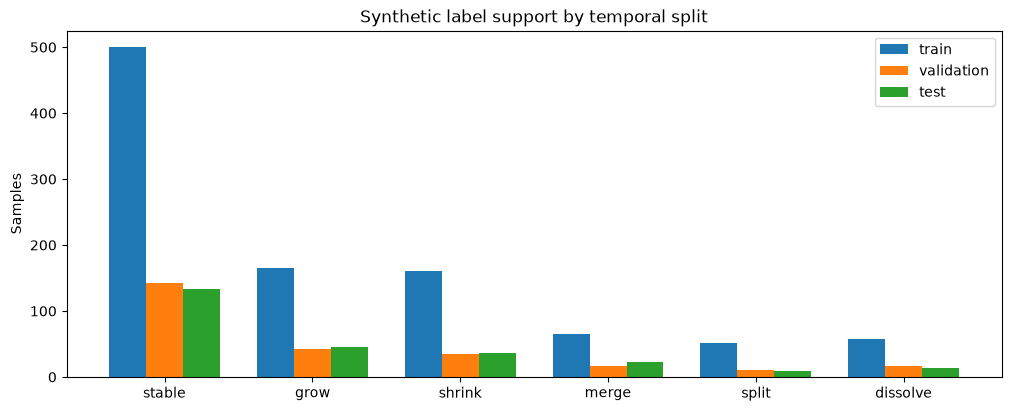

Split is by label month; preprocessing and model fitting use training rows only.


In [3]:
figures = build_prediction_figures(report)
for figure in figures.values():
    plt.close(figure)
display(figures["support"])
print("Split is by label month; preprocessing and model fitting use training rows only.")

## Baseline comparison: preserve both F1 conventions

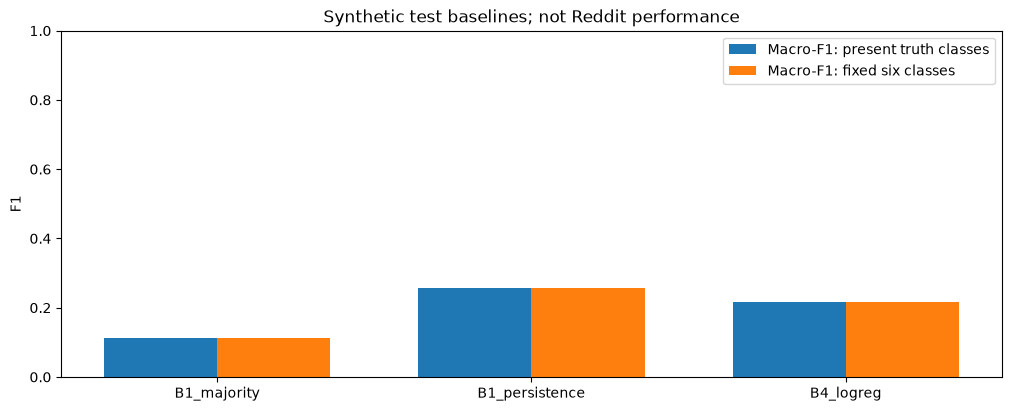

,model,split,label,precision,recall,f1,support
0,B1_majority,test,stable,0.509579,1.000000,0.675127,133
1,B1_majority,test,grow,0.000000,0.000000,0.000000,46
2,B1_majority,test,shrink,0.000000,0.000000,0.000000,37
3,B1_majority,test,merge,0.000000,0.000000,0.000000,22
4,B1_majority,test,split,0.000000,0.000000,0.000000,9
5,B1_majority,test,dissolve,0.000000,0.000000,0.000000,14
18,B1_persistence,test,stable,0.585526,0.669173,0.624561,133
19,B1_persistence,test,grow,0.452381,0.413043,0.431818,46
20,B1_persistence,test,shrink,0.400000,0.378378,0.388889,37
21,B1_persistence,test,merge,0.086957,0.090909,0.088889,22


macro_f1 averages present truth classes; macro_f1_six averages all six declared events.


In [4]:
display(figures["baselines"])
display(report["per_class"].query("split == 'test'"))
print("macro_f1 averages present truth classes; macro_f1_six averages all six declared events.")

## Every baseline confusion matrix

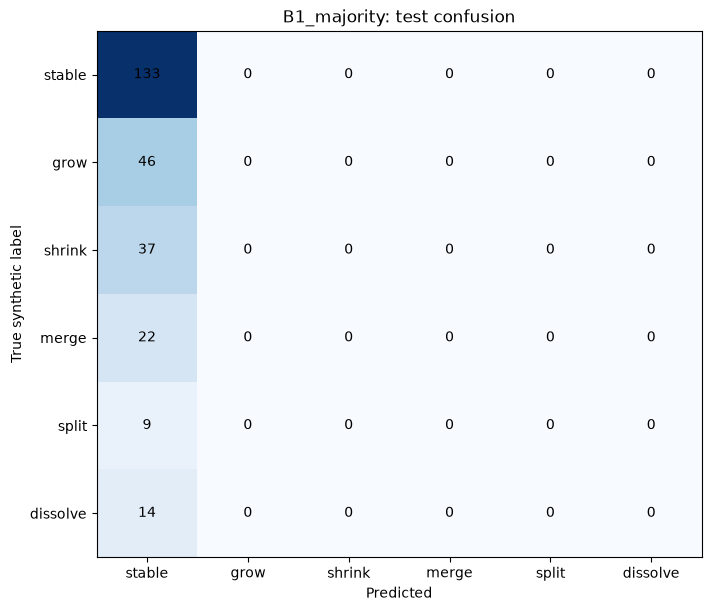

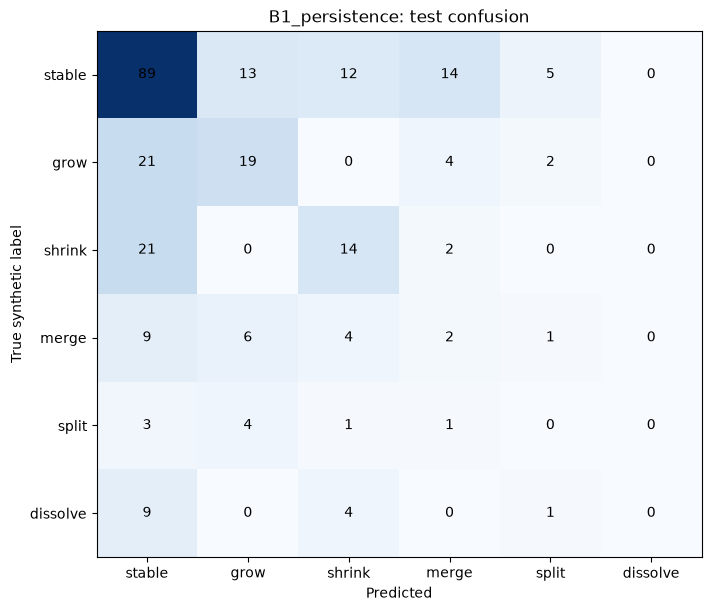

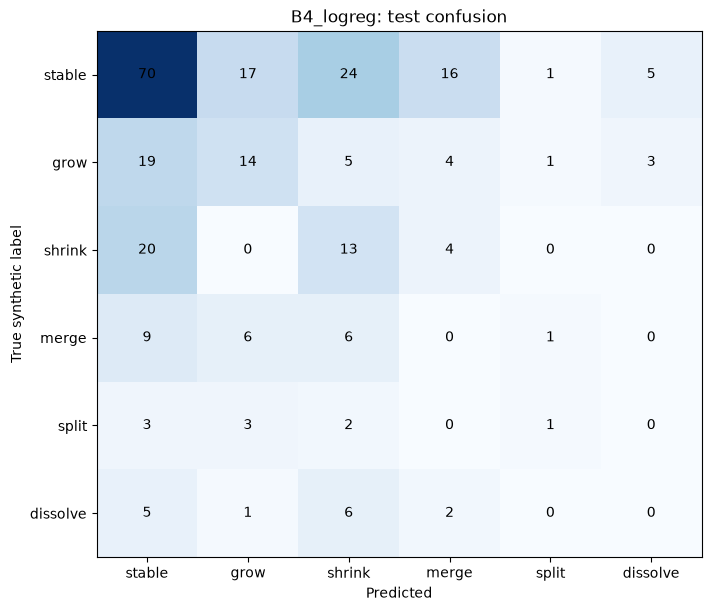

A high score on a synthetic mechanism is not evidence of social ground truth or generalization to Reddit.


In [5]:
for name, figure in figures.items():
    if name.startswith("confusion_"):
        display(figure)
print("A high score on a synthetic mechanism is not evidence of social ground truth or generalization to Reddit.")

## Actual errors and remaining research obligations

In [6]:
errors = report["predictions"].query("y_true != y_pred")
display(errors.head(30))
print("All saved prediction errors:", len(errors))
print("Inspect rare-class support and fallback rates. B2/B5/HeTCo, real-data adapters, uncertainty and ablations remain later work.")

,reference_id,feature_month,community_id,label_month,model,y_true,y_pred,used_fallback,proba_stable,proba_grow,proba_shrink,proba_merge,proba_split,proba_dissolve
0,synthetic-v1,2015-01,c0025,2015-02,B1_majority,shrink,stable,False,NaN,NaN,NaN,NaN,NaN,NaN
1,synthetic-v1,2015-01,c0030,2015-02,B1_majority,grow,stable,False,NaN,NaN,NaN,NaN,NaN,NaN
4,synthetic-v1,2015-01,c0004,2015-02,B1_majority,grow,stable,False,NaN,NaN,NaN,NaN,NaN,NaN
6,synthetic-v1,2015-01,c0033,2015-02,B1_majority,split,stable,False,NaN,NaN,NaN,NaN,NaN,NaN
8,synthetic-v1,2015-01,c0020,2015-02,B1_majority,grow,stable,False,NaN,NaN,NaN,NaN,NaN,NaN
10,synthetic-v1,2015-01,c0037,2015-02,B1_majority,shrink,stable,False,NaN,NaN,NaN,NaN,NaN,NaN
13,synthetic-v1,2015-01,c0017,2015-02,B1_majority,grow,stable,False,NaN,NaN,NaN,NaN,NaN,NaN
14,synthetic-v1,2015-01,c0019,2015-02,B1_majority,shrink,stable,False,NaN,NaN,NaN,NaN,NaN,NaN
18,synthetic-v1,2015-01,c0012,2015-02,B1_majority,shrink,stable,False,NaN,NaN,NaN,NaN,NaN,NaN
19,synthetic-v1,2015-01,c0039,2015-02,B1_majority,shrink,stable,False,NaN,NaN,NaN,NaN,NaN,NaN


All saved prediction errors: 2506
Inspect rare-class support and fallback rates. B2/B5/HeTCo, real-data adapters, uncertainty and ablations remain later work.
